### Chapter 6 Question 1

In [75]:
# imports
import igraph as ig
import numpy as np
import os
import pandas as pd
from collections import defaultdict
import scipy.sparse.linalg as lg
import random
from abcd_graph import ABCDGraph, ABCDParams
import subprocess
from sklearn.metrics import adjusted_mutual_info_score as AMI
from sklearn.metrics import adjusted_rand_score as ARI
from sklearn.cluster import KMeans
from tqdm import tqdm
import fastnode2vec as n2v
import partition_igraph
import umap.umap_ as umap
import matplotlib.pyplot as plt
from geopy.distance import geodesic
from scipy.spatial.distance import pdist, squareform

# colours
cls_edges = 'gainsboro'
cls = ['white','gray','dimgray','black']
# locations of the Julia and CGE Julia code
julia = '/Users/andrey/.juliaup/bin/julia '
CGE = '../CGE/CGE_CLI.jl '

Generate ABCD graphs with the given set of parameters (additional parameters taken from chapter 5 Notebook):

In [2]:
n = 1000
xi = 0.2

## degrees
gamma = 2.5
delta = 5
Delta = 50

## communities
beta = 1.5
s = 75
S = 150

np.random.seed(321)
random.seed(321)
params = ABCDParams(vcount=n, gamma=gamma, min_degree=delta, max_degree=Delta, beta=beta, min_community_size=s, max_community_size=S, xi=xi)
g = ABCDGraph(params).build()
ABCD = g.exporter.to_igraph()

Let's also take Hope, JS, saveEmbedding, readEmbedding and test_embeddings functions from Chapter 6 Notebook. I modified test_embeddings to only run two algorithms: HOPE with the 'katz' similarity measure and Node2Vec with fixed parameters (p=1, q=1) to simplify the evaluation and focus on comparing just these two embedding methods across dimensions.

In [15]:
## Hope embedding with various similarity functions
def Hope(g, sim='katz', dim=2, verbose=False, beta=.01, alpha=.5):
    ## For undirected graphs, embedding as source and target are identical
    if g.is_directed() == False:
        dim = dim*2
    A = np.array(g.get_adjacency().data)
    beta = beta
    alpha = alpha
    n = g.vcount()
    ## Katz
    if sim == 'katz':
        M_g = np.eye(n) - beta * A
        M_l = beta * A
    ## Adamic-Adar
    if sim == 'aa':
        M_g = np.eye(n)
        ## fix bug 1/x and take log();
        D = np.diag([1/np.log(x) if x>1 else 0 for x in g.degree()]) 
        # D = np.diag([1/np.log(max(2,x)) for x in g.degree()]) 
        M_l = np.dot(np.dot(A,D),A)
        np.fill_diagonal(M_l,0)
    ## Common neighbors
    if sim == 'cn':
        M_g = np.eye(n)
        M_l = np.dot(A,A)
    ## presonalized page rank
    if sim == 'ppr':
        P = []
        for i in range(n):
            s = np.sum(A[i])
            if s>0:
                P.append([x/s for x in A[i]])
            else:
                P.append([1/n for x in A[i]])
        P = np.transpose(np.array(P)) ## fix bug - take transpose
        M_g = np.eye(n)-alpha*P
        M_l = (1-alpha)*np.eye(n)
    S = np.dot(np.linalg.inv(M_g), M_l)
    u, s, vt = lg.svds(S, k=dim // 2)
    X1 = np.dot(u, np.diag(np.sqrt(s)))
    X2 = np.dot(vt.T, np.diag(np.sqrt(s)))
    X = np.concatenate((X1, X2), axis=1)
    p_d_p_t = np.dot(u, np.dot(np.diag(s), vt))
    eig_err = np.linalg.norm(p_d_p_t - S)
    if verbose:
        print('SVD error (low rank): %f' % eig_err)
    ## undirected graphs have identical source and target embeddings
    if g.is_directed() == False:
        d = dim//2
        return X[:,:d]
    else:
        return X


def JS(edge_file, comm_file, embed_file, return_local=True, seed=123):
    x = julia+' '+CGE+' -g '+edge_file+' -c '+comm_file+' -e '+embed_file+' --seed'+str(seed)+' 2>_stderr'
    s = subprocess.run(x, shell=True, stdout=subprocess.PIPE)
    x = s.stdout.decode().split(',')
    if return_local:
        return (float(x[1]),float(x[5]))
    else:
        return float(x[1])



def saveEmbedding(X, g, fn='_embed'):
    with open(fn,'w') as f:
        f.write(str(X.shape[0]) + " " + str(X.shape[1])+'\n')
        for i in range(X.shape[0]):
            f.write(g.vs[i]['name']+' ')
            for j in range(X.shape[1]):
                f.write(str(X[i][j])+' ')
            f.write('\n')


def readEmbedding(fn="_embed"):
    D = pd.read_csv(fn, sep=' ', skiprows=1, header=None)
    D = D.dropna(axis=1)
    Y = np.array(D.iloc[:,1:])
    return Y



def test_embeddings(G, edgefile, commfile, Dims=[2, 4, 8], local=False, verbose=False, seed=123):
    results = []
    best_jsd = float('inf')
    worst_jsd = float('-inf')

    np.random.seed(seed)
    random.seed(seed)

    sim = 'katz'  # only one similarity function
    for dim in Dims:
        X = Hope(G, sim=sim, dim=dim)
        saveEmbedding(X, G, fn='_embed')
        div = JS(edgefile, commfile, '_embed', return_local=True)
        jsd = div[int(local)]
        
        if verbose:
            print(f'HOPE ({sim}), dim={dim}, JSD={jsd:.4f}')
        
        # Save best/worst
        if jsd < best_jsd:
            os.system('cp _embed _embed_best')
            best_jsd = jsd
        if jsd > worst_jsd:
            os.system('cp _embed _embed_worst')
            worst_jsd = jsd

        results.append([dim, 'hope', sim, div[0], div[1]])

    graph = n2v.Graph(G.to_tuple_list(), directed=False, weighted=False)
    for dim in Dims:
        nv = n2v.Node2Vec(graph, dim=dim, p=1, q=1, walk_length=80, window=5, seed=seed)
        nv.train(epochs=10, verbose=False)
        Y = np.array([nv.wv[i] for i in range(len(nv.wv))])
        saveEmbedding(Y, G, fn='_embed')
        div = JS(edgefile, commfile, '_embed', return_local=True)
        jsd = div[int(local)]

        if verbose:
            print(f'Node2Vec, dim={dim}, JSD={jsd:.4f}')

        if jsd < best_jsd:
            os.system('cp _embed _embed_best')
            best_jsd = jsd
        if jsd > worst_jsd:
            os.system('cp _embed _embed_worst')
            worst_jsd = jsd

        results.append([dim, 'node2vec', 'p=1 q=1', div[0], div[1]])

    # wrap in DataFrame
    df = pd.DataFrame(results, columns=['dim', 'algo', 'param', 'jsd', 'local_jsd'])
    sort_col = 'local_jsd' if local else 'jsd'
    return df.sort_values(by=sort_col)


The CGE_CLI (Comparing Graph Embeddings Command Line Interface) requires two input files: .edgelist and .communities.

This function creates these files for both ABCD graphs (using ground truth communities) and RoC graphs (using clique-based communities):

In [67]:
def create_cge_input_files(G, prefix='graph'):
    # create edge list file
    with open(f'{prefix}.edgelist', 'w') as f:
        for edge in G.get_edgelist():
            f.write(f"{edge[0]} {edge[1]}\n")
    
    # create community file
    # For ABCD graph, communities are in 'ground_truth_community'
    # For RoC graph, each clique is a community
    if 'ground_truth_community' in G.vs.attributes():
        comm_attr = 'ground_truth_community'
    else:
        # for RoC, assign communities based on cliques
        comm_attr = 'comm'
        if 'comm' not in G.vs.attributes():
            G.vs['comm'] = G.connected_components().membership
    
    with open(f'{prefix}.communities', 'w') as f:
        for i, comm in enumerate(G.vs[comm_attr]):
            f.write(f"{i} {comm}\n")

In [17]:
create_cge_input_files(ABCD, prefix='abcd')

Now, let's run Node2Vec (with p=1 and q=1) and HOPE with Katz Index 30 times for each dimension and find the best and most stable embeddings:

In [ ]:
dimensions = [2, 4, 8, 16, 32, 64]

# ensure 'name' attribute exists on the graph
if 'name' not in ABCD.vs.attributes():
    ABCD.vs['name'] = [str(i) for i in range(ABCD.vcount())]

all_results = []

for i in range(30):
    df = test_embeddings(
        ABCD,
        edgefile='abcd.edgelist',
        commfile='abcd.communities',
        Dims=dimensions,
        local=False,
        verbose=False,
        seed=i # unique seed per run
    )
    df['run'] = i
    all_results.append(df)

# combine into one DataFrame
combined_results = pd.concat(all_results, ignore_index=True)

In [24]:
mean_scores = (combined_results.groupby(['dim', 'algo'])['jsd'].mean().reset_index(name='mean_jsd'))

summary = pd.merge(mean_scores, stability, on=['dim', 'algo'])

print(summary)

summary['param'] = ''
summary.loc[summary['algo'] == 'hope', 'param'] = 'katz'
summary.loc[summary['algo'] == 'n2v', 'param'] = 'p=1 q=1'

# the best (lowest mean JSD) and most stable (lowest std)
best_row = summary.loc[summary['mean_jsd'].idxmin()]
stable_row = summary.loc[summary['jsd'].idxmin()]

print("Best Embedding:")
print("Algorithm:", best_row['algo'])
print("Dimension:", best_row['dim'])
print("Mean JSD:", round(best_row['mean_jsd'], 6))
print("Std Dev:", round(best_row['jsd'], 6))

print("\nMost Stable Embedding:")
print("Algorithm:", stable_row['algo'])
print("Dimension:", stable_row['dim'])
print("Mean JSD:", round(stable_row['mean_jsd'], 6))
print("Std Dev:", round(stable_row['jsd'], 6))


    dim  algo  mean_jsd       jsd
0     2  hope  0.192427  0.002358
1     2   n2v  0.180405  0.003304
2     4  hope  0.122434  0.018250
3     4   n2v  0.033763  0.002884
4     8  hope  0.044012  0.013247
5     8   n2v  0.001422  0.000148
6    16  hope  0.046451  0.013395
7    16   n2v  0.000261  0.000017
8    32  hope  0.059782  0.014556
9    32   n2v  0.000147  0.000011
10   64  hope  0.045825  0.020773
11   64   n2v  0.000201  0.000064

Best Embedding:
Algorithm: n2v
Dimension: 32
Mean JSD: 0.000147
Std Dev: 1.1e-05

Most Stable Embedding:
Algorithm: n2v
Dimension: 32
Mean JSD: 0.000147
Std Dev: 1.1e-05


### Chapter 6 Question 2

Now, let's use the obtained embeddings to run the k-means algorithm using the known number of communities from the ABCD graph and compare the quality of the embeddings using AMI, ARI, and AGRI:

In [28]:
# load the best and worst embeddings that were already saved by test_embeddings
X_best = readEmbedding(fn="_embed_best")
X_worst = readEmbedding(fn="_embed_worst")

# the ground truth communities
ground_truth = ABCD.vs['ground_truth_community']
n_communities = max(ground_truth) + 1


kmeans_best = KMeans(n_clusters=n_communities, random_state=123, n_init="auto").fit(X_best)
kmeans_worst = KMeans(n_clusters=n_communities, random_state=123, n_init="auto").fit(X_worst)


# evaluation metrics
# AMI
ami_best = AMI(ground_truth, kmeans_best.labels_)
ami_worst = AMI(ground_truth, kmeans_worst.labels_)

ari_best = ARI(ground_truth, kmeans_best.labels_)
ari_worst = ARI(ground_truth, kmeans_worst.labels_)

# AGRI
true_labels = {i: ground_truth[i] for i in range(len(ground_truth))}
pred_best = {i: kmeans_best.labels_[i] for i in range(len(kmeans_best.labels_))}
pred_worst = {i: kmeans_worst.labels_[i] for i in range(len(kmeans_worst.labels_))}

agri_best = ABCD.gam(true_labels, pred_best)
agri_worst = ABCD.gam(true_labels, pred_worst)


print("Best embedding:")
print("AMI:", round(ami_best, 4), "ARI:", round(ari_best, 4), "AGRI:", round(agri_best, 4))
print("Worst embedding:")
print("AMI:", round(ami_worst, 4), "ARI:", round(ari_worst, 4), "AGRI:", round(agri_worst, 4))

Best embedding:
AMI: 1.0 ARI: 1.0 AGRI: 1.0
Worst embedding:
AMI: 0.2835 ARI: 0.1052 AGRI: 0.0649


The best embedding perfectly recovered the ground truth communities, with AMI, ARI, and AGRI all equal to 1.0. In contrast, the worst embedding performed much worse, showing low scores across all metrics, implying that it didn't capture the community structure well.

### Chapter 6 Question 3

First, let's take a ring of cliques function from Chapter 5 notebook and generate the graph with $l$ = 10 cliques and of size $s$ = 3:

In [30]:
def ringOfCliques(n, s):
    roc = ig.Graph.Erdos_Renyi(n=n*s,p=0)
    ## cliques
    for i in range(n):
        for j in np.arange(s*i,s*(i+1)):
            for k in np.arange(j+1,s*(i+1)):
                roc.add_edge(j,k)
    ## ring
    for i in range(n):
        if i>0:
            roc.add_edge(s*i-1,s*i)
        else:
            roc.add_edge(n*s-1,0)
    roc.vs['size'] = 8
    roc.vs['color'] = cls[2]
    roc.es['color'] = cls_edges
    return roc

roc = ringOfCliques(10,3)

Create input files:

In [35]:
# ensure vertex names exist
if 'name' not in roc.vs.attributes():
    roc.vs['name'] = [str(i) for i in range(roc.vcount())]

create_cge_input_files(roc, prefix='roc')

Now, let's run embedding and divergence evaluation. In Figure 5.14, the graph was generated with ω = 10 cliques of size s = 3 (triangles), resulting in a graph with 30 nodes. Since the HOPE algorithm uses a truncated SVD with *k = dim / 2*, and *k* must be less than the number of nodes, I limited the dimensions to [2, 4, 8, 16], excluding 32 and 64, as it would exceed the limit for this graph.

In [39]:
dimensions = [2, 4, 8, 16]

all_results = []
for i in tqdm(range(30), desc="Generating embeddings (RoC)"):
    df = test_embeddings(
        roc,
        edgefile='roc.edgelist',
        commfile='roc.communities',
        Dims=dimensions,
        local=False,
        verbose=False,
        seed=i
    )
    df['run'] = i
    all_results.append(df)

roc_results = pd.concat(all_results, ignore_index=True)

Generating embeddings (RoC):   0%|                       | 0/30 [00:00<?, ?it/s]python(44538) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44556) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44568) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44578) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Reading graph:   0%|                                     | 0/40 [00:00<?, ?it/s]

python(44588) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44604) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44617) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44627) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Generating embeddings (RoC):   3%|▌              | 1/30 [00:21<10:20, 21.40s/it]python(44637) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44655) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44665) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44675) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Reading graph:   0%|                                     | 0/40 [00:00<?, ?it/s]

python(44691) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44701) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44711) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44721) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Generating embeddings (RoC):   7%|█              | 2/30 [00:43<10:05, 21.62s/it]python(44737) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44752) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44762) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(44778) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Reading graph:   0%|                                     | 0/40 [00:00<?, ?it/s]

... (51 outputs left out)

Reading graph:   0%|                                     | 0/40 [00:00<?, ?it/s]

python(47328) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47345) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47357) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47367) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Generating embeddings (RoC):  97%|█████████████▌| 29/30 [10:22<00:21, 21.33s/it]python(47377) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47395) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47405) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47415) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Reading graph:   0%|                                     | 0/40 [00:00<?, ?it/s]

python(47425) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47441) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47451) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(47461) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Generating embeddings (RoC): 100%|██████████████| 30/30 [10:43<00:00, 21.45s/it]


Get the best and wors embeddings and reduce them to 2D with UMAP:

In [47]:
embedding_best = readEmbedding("_embed_best")
embedding_worst = readEmbedding("_embed_worst")

U_best = umap.UMAP(n_components=2, random_state=1234).fit_transform(embedding_best)
U_worst = umap.UMAP(n_components=2, random_state=1234).fit_transform(embedding_worst)

/Users/andrey/mambaforge/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.
/Users/andrey/mambaforge/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Plot embeddings and highlight cliques:

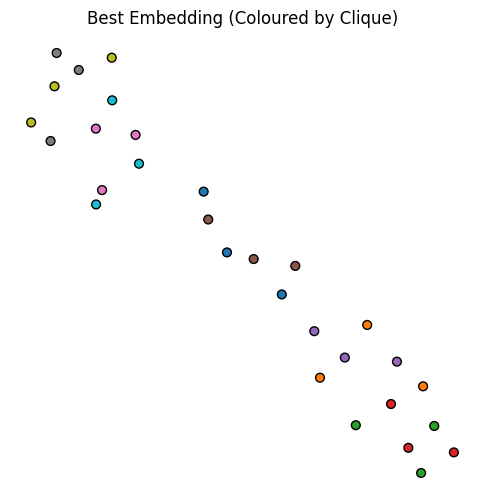

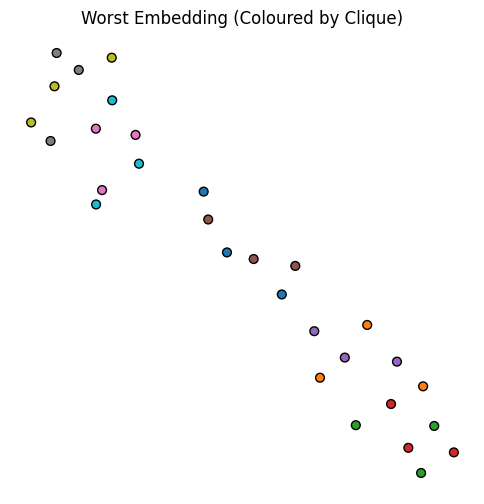

In [58]:
# community labels
colours = roc.vs['comm'] if 'comm' in roc.vs.attributes() else [0] * roc.vcount()

def plot_embedding(U, title, communities):
    plt.figure(figsize=(6, 6))
    plt.scatter(U[:, 0], U[:, 1], c=communities, cmap='tab10', s=40, edgecolor='k')
    plt.title(title)
    plt.axis('off')
    plt.show()

# assign community ID based on clique membership
roc.vs['comm'] = [i // 3 for i in range(roc.vcount())]


plot_embedding(U_best, "Best Embedding (Coloured by Clique)", roc.vs['comm'])
plot_embedding(U_worst, "Worst Embedding (Coloured by Clique)", roc.vs['comm'])

In [49]:
print("Best embedding JSD:", JS("roc.edgelist", "roc.communities", "_embed_best"))
print("Worst embedding JSD:", JS("roc.edgelist", "roc.communities", "_embed_worst"))

python(54603) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Best embedding JSD: (0.0, 0.09430000000000005)


python(54615) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Worst embedding JSD: (0.0, 0.09499999999999997)


The best and worst embeddings were almost identical, and while UMAP showed that cliques stayed somewhat grouped, many were mixed together or ended up in the same area, which makes sense given the ring structure and small size of the graph.

### Chapter 6 Question 4

Load the graph:

In [61]:
## read edge list for the grid network and build undirected simple graph
Grid = ig.Graph.Read_Ncol("gridkit_europe-highvoltage.edges", directed=False)
Grid = Grid.simplify()
## read the nodes and their attributes
Grid_attr = pd.read_csv("gridkit_europe-highvoltage.vertices")
## add the isolated nodes to the graph
isolates = set(Grid_attr.v_id).difference(set([int(x) for x in Grid.vs['name']]))
Grid.add_vertices([str(x) for x in isolates])
## build attribute dictionaries
Longitude = dict(zip(Grid_attr.v_id, Grid_attr.lon))
Latitude = dict(zip(Grid_attr.v_id, Grid_attr.lat))
Type = dict(zip(Grid_attr.v_id, Grid_attr.typ))
## map names to integers for easier referencing
Grid.vs["id"] = [int(x) for x in Grid.vs["name"]]
## save longitude, latitude and node type in the graph
Grid.vs["longitude"] = [Longitude[i] for i in Grid.vs["id"]]
Grid.vs["latitude"] = [Latitude[i] for i in Grid.vs["id"]]
Grid.vs["type"] = [Type[i] for i in Grid.vs["id"]]

Extract the giant component:

In [64]:
Grid_gc = Grid.connected_components().giant()

Generate embeddings and compute divergence:

In [68]:
create_cge_input_files(Grid_gc, prefix='grid')

In [70]:
dimensions = [2, 4, 8, 16, 32, 64]
all_results = []
for i in tqdm(range(30), desc="Generating embeddings (Grid)"):
    df = test_embeddings(
        Grid_gc,
        edgefile='grid.edgelist',
        commfile='grid.communities',
        Dims=dimensions,
        local=False,
        verbose=False,
        seed=i
    )
    df['run'] = i
    all_results.append(df)

grid_results = pd.concat(all_results, ignore_index=True)

Generating embeddings (Grid):   0%|                      | 0/30 [00:00<?, ?it/s]python(62835) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(63113) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(63379) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(63649) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(63950) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(64290) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Reading graph:   0%|                                  | 0/16922 [00:00<?, ?it/s]

python(64401) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(64492) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(64581) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(64680) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(64793) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(64923) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Generating embeddings (Grid):   3%|▎          | 1/30 [12:48<6:11:12, 768.02s/it]python(65196) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(65462) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(65744) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(66040) MallocStackLogging: can'

Reading graph:   0%|                                  | 0/16922 [00:00<?, ?it/s]

python(66813) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(66905) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(66992) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(67090) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(67200) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(67331) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Generating embeddings (Grid):   7%|▋          | 2/30 [25:51<6:02:46, 777.37s/it]python(67620) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(67889) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(68174) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(68480) MallocStackLogging: can'

Reading graph:   0%|                                  | 0/16922 [00:00<?, ?it/s]

... (8 outputs left out)

python(79007) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(79094) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(79189) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(79282) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(79392) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(79525) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Generating embeddings (Grid):  23%|██       | 7/30 [1:31:07<4:58:32, 778.80s/it]python(79797) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(80056) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(80331) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(80628) MallocStackLogging: can'

Reading graph:   0%|                                  | 0/16922 [00:00<?, ?it/s]

python(81404) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(81502) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(81593) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(81690) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(81800) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(81924) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
Generating embeddings (Grid):  27%|██▍      | 8/30 [1:44:05<4:45:27, 778.52s/it]python(82212) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(82518) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(82821) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(83141) MallocStackLogging: can'

KeyboardInterrupt: 

Due to runtime constraints on the large European Grid graph, I used only 8 randomly seeded embeddings (instead of 30) to perform the evaluation.

In [71]:
grid_results = pd.concat(all_results, ignore_index=True)
grid_results.to_csv("grid_results_partial.csv", index=False)

UMAP projection of best and worst embeddings:

In [72]:
X_best = readEmbedding('_embed_best')
X_worst = readEmbedding('_embed_worst')


U_best = umap.UMAP(n_components=2, random_state=1234).fit_transform(X_best)
U_worst = umap.UMAP(n_components=2, random_state=1234).fit_transform(X_worst)


/Users/andrey/mambaforge/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/Users/andrey/mambaforge/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Community detection using Louvain:

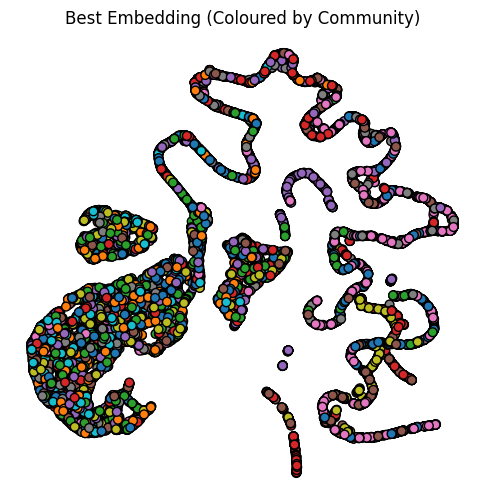

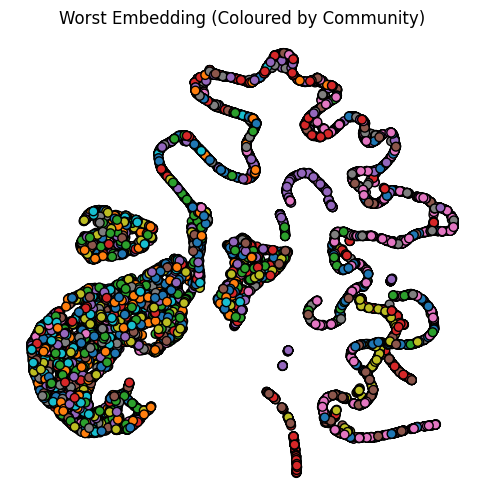

In [73]:
Grid_gc.vs['comm'] = Grid_gc.community_multilevel().membership

plot_embedding(U_best, "Best Embedding (Coloured by Community)", Grid_gc.vs['comm'])
plot_embedding(U_worst, "Worst Embedding (Coloured by Community)", Grid_gc.vs['comm'])

The best and worst embeddings produce nearly identical UMAP projections, with somewhat detectable community separation. This suggests that even the "worst" embedding (by a small divergence margin) preserved global structure well, which is a sign of robust embedding behavior on the graph.

##### (b)

Scatter plot of embedded vs geographic distances:

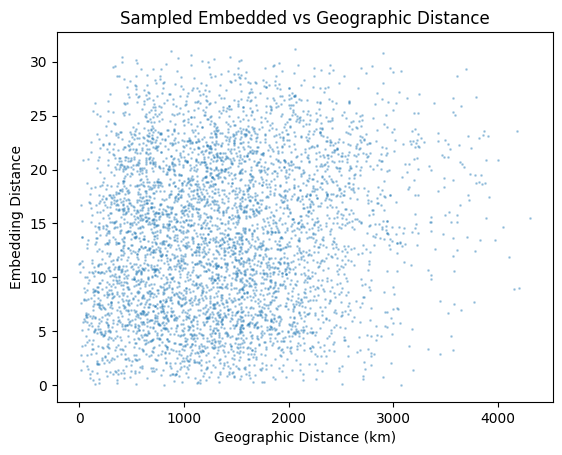

In [77]:
n = Grid_gc.vcount()
samples = random.sample([(i, j) for i in range(n) for j in range(i+1, n)], 5000)

geo_vals = [geodesic(coords[i], coords[j]).kilometers for i, j in samples]
embed_vals = [np.linalg.norm(U_best[i] - U_best[j]) for i, j in samples]

plt.figure()
plt.scatter(geo_vals, embed_vals, s=1, alpha=0.3)
plt.xlabel("Geographic Distance (km)")
plt.ylabel("Embedding Distance")
plt.title("Sampled Embedded vs Geographic Distance")
plt.show()

I ran into compute-time issues throughout this assignment, especially with the larger graphs and slow divergence evaluations, generaating embeddings for the last queston was running for several hours before I interrupted it. I tried running things over several days and took breaks just to let code finish, but unfortunateky I wasn't able to get everything fully completed in time.

##### (c)

Bucket analysis: